# k-Nearest Neighbors

Implements loading, split, training, evaluation, hyperparameter sweeps over k, metrics, weighting, neighbor analysis, and save best.

In [1]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
from IPython.display import display
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.preprocessing import LabelEncoder
import joblib

from schema_utils import detect_feature_columns, build_feature_matrix



In [3]:
# 2. Data Loading - use train/test CSVs
import os
import pandas as pd
DATA_DIR = os.path.join('..','datasets')
TRAIN_PATH = os.path.join(DATA_DIR, 'training_data_train.csv')
TEST_PATH = os.path.join(DATA_DIR, 'training_data_test.csv')
if not os.path.exists(TRAIN_PATH) or not os.path.exists(TEST_PATH):
    raise FileNotFoundError("Missing train/test CSVs in ../datasets: training_data_train.csv and training_data_test.csv")
df_train = pd.read_csv(TRAIN_PATH)
df_test = pd.read_csv(TEST_PATH)
from schema_utils import detect_feature_columns
schema = detect_feature_columns(df_train)
if not schema['label_col']:
    raise ValueError('No label column detected. Expected one of: label/class/target')
label_col = schema['label_col']
print('Train size:', len(df_train), 'Test size:', len(df_test))
print('Train balance:', df_train[label_col].value_counts(normalize=True))
print('Test balance:', df_test[label_col].value_counts(normalize=True))



Train size: 1421 Test size: 433
Train balance: label
human      0.590429
nothing    0.409571
Name: proportion, dtype: float64
Test balance: label
human      0.505774
nothing    0.494226
Name: proportion, dtype: float64


In [4]:
# 3-4. Features + Split (pre-split train/test, train-only fit)
import numpy as np
from schema_utils import build_feature_matrix
feature_cols = schema['classic_feature_cols']
X_train_all = build_feature_matrix(df_train, feature_cols)
X_test_all = build_feature_matrix(df_test, feature_cols)
# Fill NaNs using training medians
train_medians = np.nanmedian(X_train_all, axis=0)
X_train_all = np.where(np.isnan(X_train_all), train_medians, X_train_all)
X_test_all = np.where(np.isnan(X_test_all), train_medians, X_test_all)
# Labels
y_str_train = df_train[label_col].astype(str).values
y_str_test = df_test[label_col].astype(str).values
from sklearn.preprocessing import LabelEncoder, StandardScaler
le = LabelEncoder()
y_train = le.fit_transform(y_str_train)
y_test = le.transform(y_str_test)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_all)
X_test = scaler.transform(X_test_all)
print('Train shape:', X_train.shape, 'Test shape:', X_test.shape)
print('Classes:', list(le.classes_))



Train shape: (1421, 46) Test shape: (433, 46)
Classes: ['human', 'nothing']


Training accuracy: 1.0
Test accuracy: 0.9561200923787528
Confusion matrix: [[201  18]
 [  1 213]]
              precision    recall  f1-score   support

       human       1.00      0.92      0.95       219
     nothing       0.92      1.00      0.96       214

    accuracy                           0.96       433
   macro avg       0.96      0.96      0.96       433
weighted avg       0.96      0.96      0.96       433



,k,test_accuracy
0,1,0.960739
1,3,0.960739
2,5,0.956120
3,7,0.965358
4,9,0.960739
5,11,0.965358
6,15,0.963048
7,20,0.963048


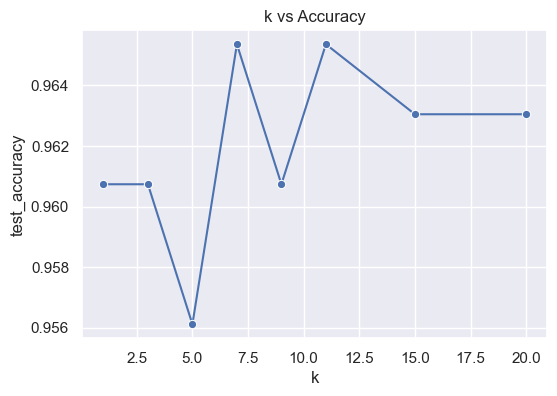

Best k: 7


,metric,test_accuracy
0,manhattan,0.965358
1,manhattan,0.965358
2,chebyshev,0.849885


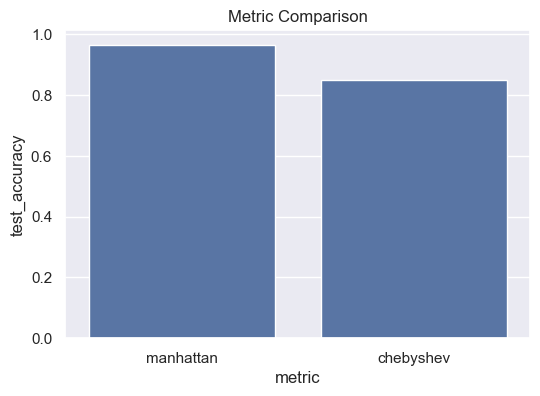

,weights,test_accuracy
0,uniform,0.965358
1,distance,0.965358


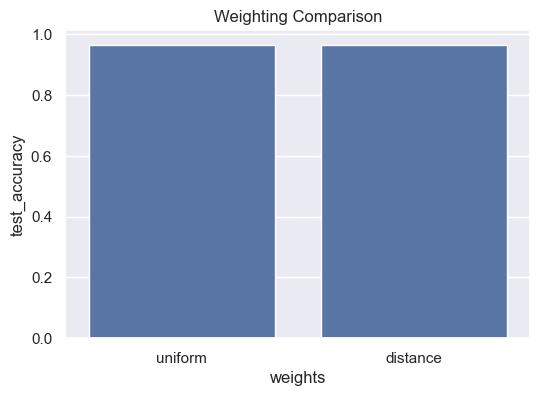

Distances: [33.19349502 34.3951653  34.43212784 35.65806277 36.18376996 36.43961202
 36.9476734 ]
Neighbor labels: ['human' 'human' 'human' 'human' 'human' 'human' 'human']
Majority vote prediction: human
Saved best model as knn.pkl


In [7]:

from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5, weights='distance', metric='manhattan')
knn.fit(X_train, y_train)
training_accuracy = knn.score(X_train, y_train)
test_accuracy = knn.score(X_test, y_test)
print('Training accuracy:', training_accuracy)
print('Test accuracy:', test_accuracy)

y_pred = knn.predict(X_test)
print('Confusion matrix:', confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=list(le.classes_)))

# Sweep k values
ks = [1, 3, 5, 7, 9, 11, 15, 20]
res = []
for k in ks:
    m = KNeighborsClassifier(n_neighbors=k, weights='distance', metric='manhattan')
    m.fit(X_train, y_train)
    res.append({'k': k, 'test_accuracy': m.score(X_test, y_test)})
dfk = pd.DataFrame(res)
display(dfk)
plt.figure(figsize=(6,4)); sns.lineplot(x='k', y='test_accuracy', data=dfk, marker='o'); plt.title('k vs Accuracy'); plt.show()
best_k = max(res, key=lambda r: r['test_accuracy'])['k']
print('Best k:', best_k)

# Distance metrics comparison
metrics = ['manhattan', 'manhattan', 'chebyshev']
mres = []
for mtr in metrics:
    m = KNeighborsClassifier(n_neighbors=best_k, weights='distance', metric=mtr)
    m.fit(X_train, y_train)
    mres.append({'metric': mtr, 'test_accuracy': m.score(X_test, y_test)})
mdf = pd.DataFrame(mres)
display(mdf)
plt.figure(figsize=(6,4)); sns.barplot(x='metric', y='test_accuracy', data=mdf); plt.title('Metric Comparison'); plt.show()

# Weighting comparison
weights = ['uniform', 'distance']
wres = []
for w in weights:
    m = KNeighborsClassifier(n_neighbors=best_k, weights=w, metric='manhattan')
    m.fit(X_train, y_train)
    wres.append({'weights': w, 'test_accuracy': m.score(X_test, y_test)})
wdf = pd.DataFrame(wres)
display(wdf)
plt.figure(figsize=(6,4)); sns.barplot(x='weights', y='test_accuracy', data=wdf); plt.title('Weighting Comparison'); plt.show()

# Sample prediction neighbor analysis
sample_idx = 0
D, Idx = knn.kneighbors(X_test[sample_idx].reshape(1,-1), n_neighbors=best_k, return_distance=True)
neighbor_labels = le.inverse_transform(y_train[Idx[0]])
print('Distances:', D[0])
print('Neighbor labels:', neighbor_labels)
print('Majority vote prediction:', le.inverse_transform([knn.predict(X_test[sample_idx].reshape(1,-1))[0]])[0])

# Save best model
best_model = KNeighborsClassifier(n_neighbors=best_k, weights='distance', metric='manhattan')
best_model.fit(np.vstack([X_train,X_test]), np.hstack([y_train,y_test]))
joblib.dump(best_model, os.path.join('..','models','knn.pkl'))
print('Saved best model as knn.pkl')


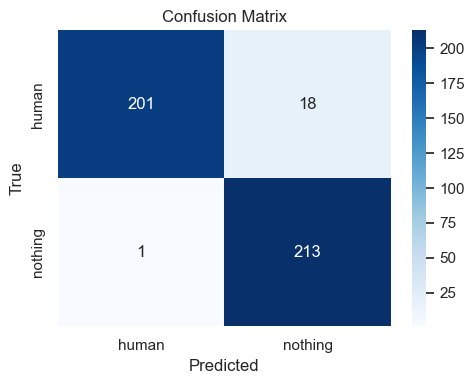

              precision    recall  f1-score   support

       human       1.00      0.92      0.95       219
     nothing       0.92      1.00      0.96       214

    accuracy                           0.96       433
   macro avg       0.96      0.96      0.96       433
weighted avg       0.96      0.96      0.96       433



In [8]:

# Confusion Matrix - Visualize mistakes
from sklearn.metrics import confusion_matrix, classification_report
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=list(le.classes_), yticklabels=list(le.classes_))
plt.title('Confusion Matrix')
plt.ylabel('True'); plt.xlabel('Predicted')
plt.tight_layout(); plt.show()
print(classification_report(y_test, y_pred, target_names=list(le.classes_)))
